# Annual GDP development

This workbook uses reusable functions to load, clean, compare, and plot World Bank
annual GDP. Edit **fed/settings.py** to select countries, years, and the index base,
then restart the notebook kernel and run all cells.

The default exercise covers the United Kingdom, United States, Brazil, Japan,
China, Germany, and Switzerland. The task list includes all seven countries.

GDP is measured in **constant 2015 US dollars**: an inflation-adjusted measure of
total output. It is not GDP per person or a purchasing-power-parity measure.
Population and reference-year exchange rates affect comparisons of economy size.

Sources: [World Bank indicator](https://data.worldbank.org/indicator/NY.GDP.MKTP.KD)
and [constant-dollar methodology](https://datahelpdesk.worldbank.org/knowledgebase/articles/114943-how-do-you-derive-constant-price-series-in-usd).
The saved response and retrieval metadata document the source (World Bank, CC BY 4.0).
Historical estimates can subsequently be revised.

In [1]:
import json
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from fed import settings
from fed.data import load_gdp, clean_gdp
from fed.analysis import add_growth_measures, summarize_gdp, describe_gdp
from fed.plot_utils import plot_gdp, plot_annual_growth

start, end, countries = settings.selection()
base_year = settings.BASE_YEAR
if start == end:
    raise ValueError("Choose at least two years for this growth analysis")
if not start <= base_year <= end:
    raise ValueError("Choose BASE_YEAR within START_YEAR and END_YEAR in fed/settings.py")
settings.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
settings.PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.size": 11, "figure.dpi": 120})
display(Markdown(
    f"## Selection: {start}–{end}\n\n"
    f"Countries: {', '.join(countries.values())}. "
    f"Units: {settings.UNITS}. Index base: {base_year} = 100."
))

## Selection: 2000–2022

Countries: United Kingdom, United States, Brazil, Japan, China, Germany, Switzerland. Units: constant 2015 US$. Index base: 2000 = 100.

## 1. Load and inspect

The loader reads the saved snapshot offline and checks that it covers the
selection. To deliberately download another selection, call load_gdp(refresh=True)
with internet access, then rerun the notebook. Refreshing replaces the snapshot,
so it should be an explicit choice.

All data and output paths are found from the installed project, independently of
the folder from which you open this notebook.

In [2]:
raw = load_gdp(start_year=start, end_year=end, countries=countries)
metadata = json.loads(settings.RAW_PATH.with_suffix(".metadata.json").read_text(encoding="utf-8"))
display(metadata)
display(raw.head())
print(f"Selected raw rows: {len(raw)}; missing GDP values: {raw.gdp_usd.isna().sum()}")

{'url': 'https://api.worldbank.org/v2/country/GBR;USA;BRA;JPN;CHN;DEU;CHE/indicator/NY.GDP.MKTP.KD?date=2000:2022&format=json&per_page=1000',
 'retrieved_at_utc': '2026-10-21T15:42:38.608868+00:00',
 'indicator': 'NY.GDP.MKTP.KD',
 'units': 'constant 2015 US$',
 'frequency': 'annual',
 'source_last_updated': '2026-10-08',
 'license': 'CC BY 4.0',
 'license_url': 'https://creativecommons.org/licenses/by/4.0/'}

,country_code,country,year,gdp_usd
0,BRA,Brazil,2022,1.899505e+12
1,BRA,Brazil,2021,1.843881e+12
2,BRA,Brazil,2020,1.760057e+12
3,BRA,Brazil,2019,1.819683e+12
4,BRA,Brazil,2018,1.797737e+12


Selected raw rows: 161; missing GDP values: 0


## 2. Clean and validate

The cleaner normalizes codes and names, converts numeric fields, restricts the
selection, removes identical duplicates, and sorts the table. It rejects missing
country-year pairs, conflicting records, and invalid values. It never interpolates
or replaces a missing GDP value with zero.

A tidy row represents one country in one year. The original snapshot is preserved.

In [3]:
data = clean_gdp(raw, start, end, countries=countries)
expected_rows = len(countries) * (end - start + 1)
assert len(data) == expected_rows
coverage = data.groupby("country").agg(
    first_year=("year", "min"), last_year=("year", "max"), observations=("year", "count")
)
display(coverage)
processed_path = settings.PROCESSED_DIR / f"gdp_{start}_{end}.csv"
data.to_csv(processed_path, index=False)
measures = add_growth_measures(data, base_year=base_year)
summary = summarize_gdp(data, start, end)
summary.to_csv(settings.output_path("summary", start, end, "csv"))
display(summary.style.format({
    "start_gdp_usd": "{:,.0f}", "end_gdp_usd": "{:,.0f}",
    "total_change_pct": "{:.1f}", "cagr_pct": "{:.2f}"
}))

,first_year,last_year,observations
country,,,
Brazil,2000,2022,23
China,2000,2022,23
Germany,2000,2022,23
Japan,2000,2022,23
Switzerland,2000,2022,23
United Kingdom,2000,2022,23
United States,2000,2022,23


,start_gdp_usd,end_gdp_usd,total_change_pct,cagr_pct
country,,,,
China,"2,824,916,263,543","16,706,452,162,504",491.4,8.41
Brazil,"1,186,419,100,641","1,899,505,377,558",60.1,2.16
United States,"13,717,679,619,695","21,483,388,181,185",56.6,2.06
Switzerland,"538,339,395,343","819,432,798,586",52.2,1.93
United Kingdom,"2,314,307,169,244","3,274,265,196,937",41.5,1.59
Germany,"2,885,963,533,943","3,727,790,994,178",29.2,1.17
Japan,"4,030,991,750,951","4,685,724,442,189",16.2,0.69


## 3. Compare GDP levels

Each line shows total economic output in trillions of constant 2015 US dollars.
The common scale shows differences in economy size.

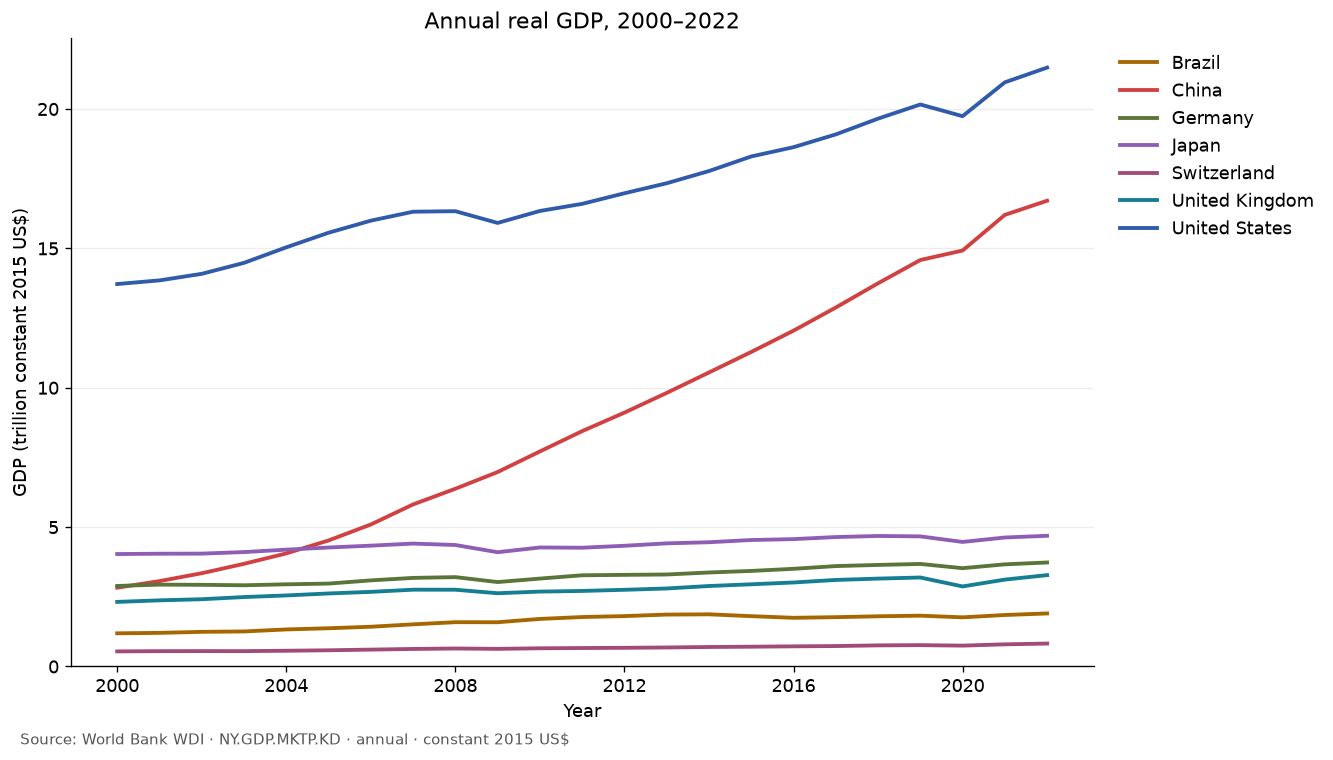

In [4]:
fig, ax = plot_gdp(data)
fig.savefig(settings.output_path("gdp_levels", start, end, "png"), dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

## 4. Compare proportional growth

Setting each country's GDP in the base year to 100 removes differences in starting
size. An index of 150 means output is 50% above its base-year value.

Cumulative change is (end GDP / start GDP - 1) * 100. Compound annual growth
(CAGR) is ((end GDP / start GDP) ** (1 / years elapsed) - 1) * 100.

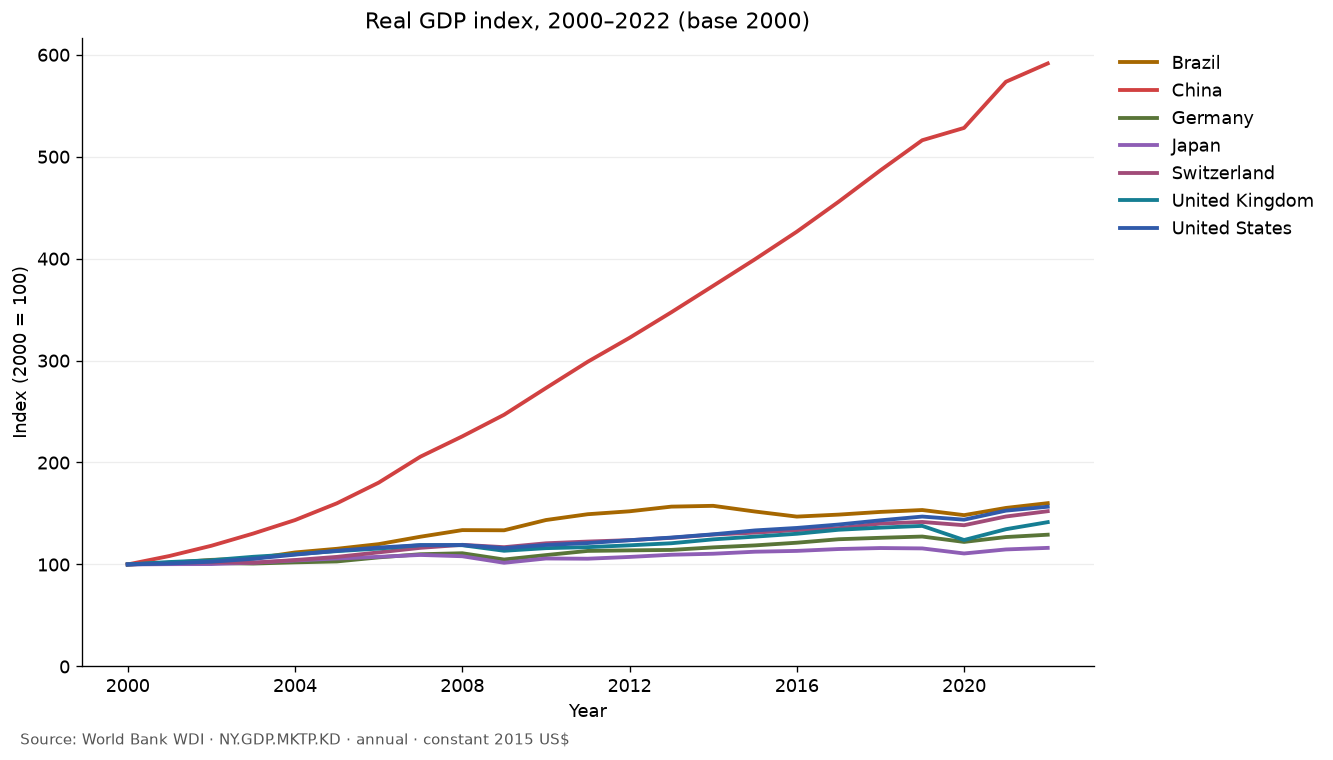

In [5]:
fig, ax = plot_gdp(data, indexed=True, base_year=base_year)
fig.savefig(settings.output_path("gdp_index", start, end, "png"), dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

## 5. Compare annual changes

Annual growth is the percentage change from the previous year. The first year's
growth is undefined because the preceding year is outside this selection.
A change across a missing year is also undefined. Shared vertical scales make
the country panels comparable.

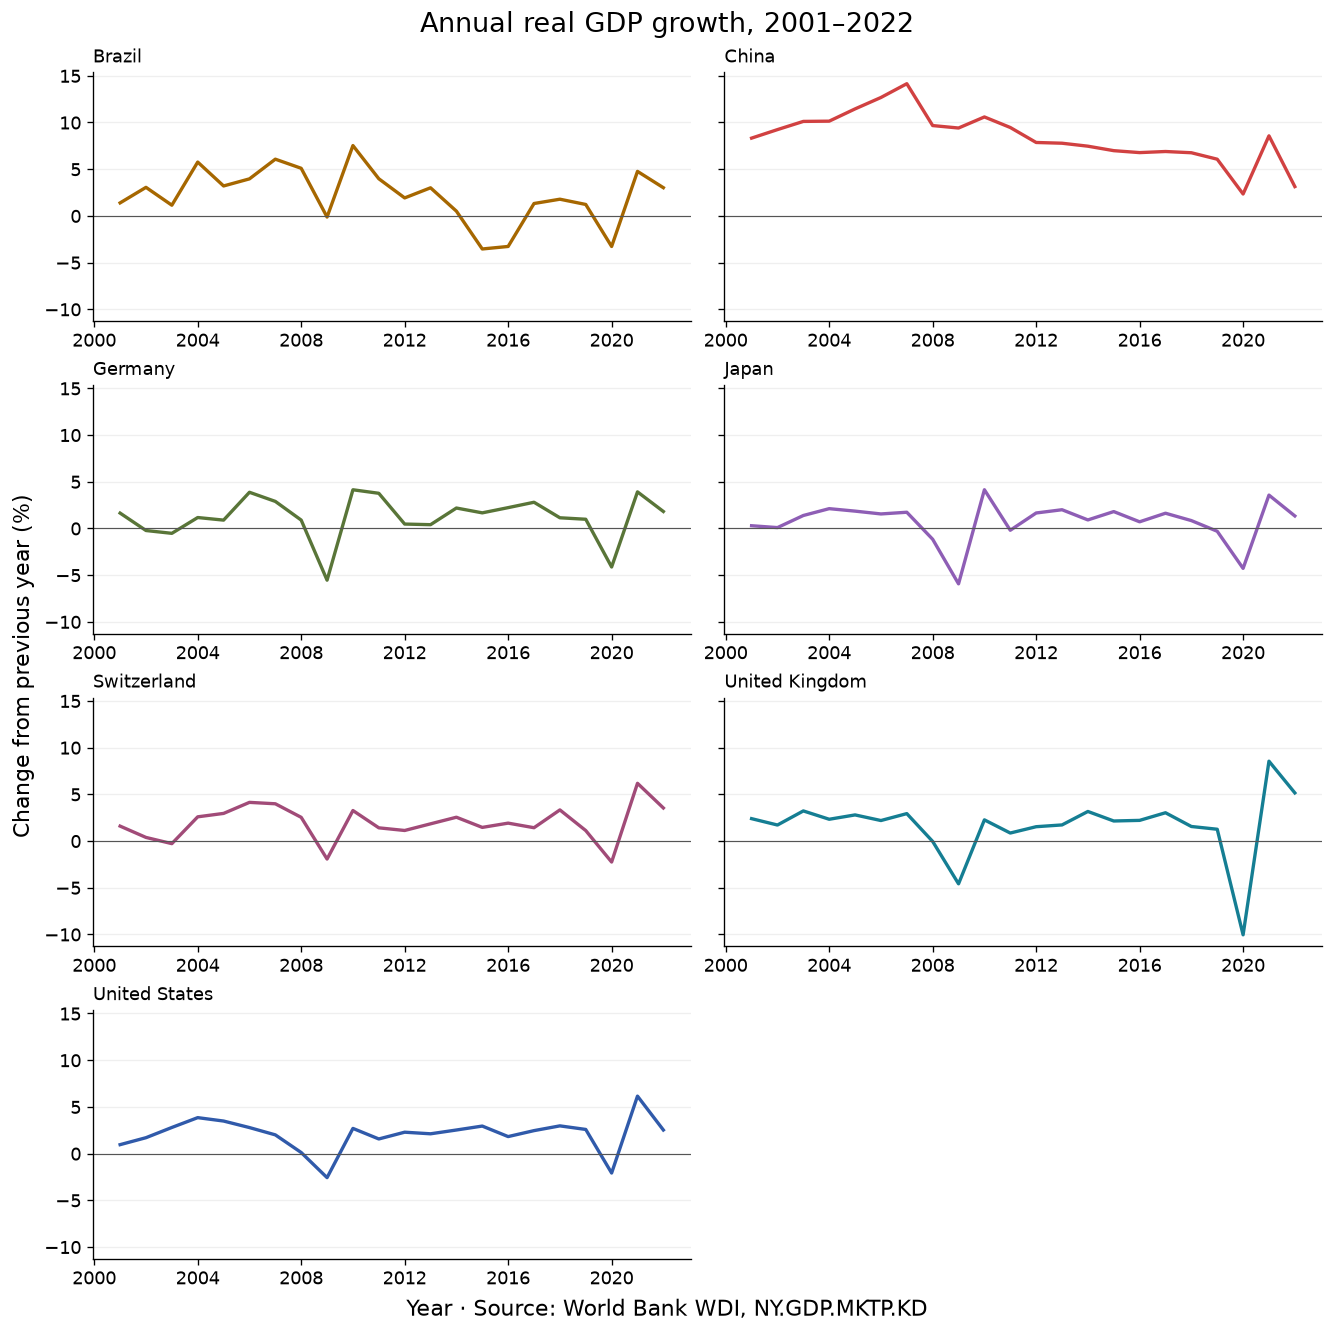

year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,...,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
country,,,,,,,,,,,,,,,,,,,,,
Brazil,NaN,1.39,3.05,1.14,5.76,3.20,3.96,6.07,5.09,-0.13,...,3.00,0.50,-3.55,-3.28,1.32,1.78,1.22,-3.28,4.76,3.02
China,NaN,8.32,9.24,10.11,10.14,11.45,12.68,14.15,9.67,9.41,...,7.78,7.46,6.98,6.77,6.89,6.76,6.07,2.34,8.57,3.13
Germany,NaN,1.64,-0.23,-0.53,1.16,0.89,3.87,2.89,0.89,-5.54,...,0.40,2.18,1.66,2.22,2.80,1.14,0.98,-4.13,3.91,1.81
Japan,NaN,0.28,0.08,1.38,2.11,1.85,1.55,1.73,-1.17,-5.94,...,2.00,0.91,1.80,0.70,1.62,0.83,-0.31,-4.28,3.56,1.33
Switzerland,NaN,1.59,0.38,-0.28,2.59,2.95,4.13,3.98,2.53,-1.93,...,1.84,2.54,1.45,1.91,1.42,3.33,1.12,-2.26,6.18,3.53
United Kingdom,NaN,2.39,1.71,3.22,2.33,2.79,2.19,2.93,-0.05,-4.59,...,1.72,3.16,2.14,2.21,3.02,1.55,1.26,-10.05,8.54,5.15
United States,NaN,0.96,1.70,2.80,3.85,3.48,2.78,2.00,0.11,-2.58,...,2.12,2.52,2.95,1.82,2.46,2.97,2.58,-2.08,6.15,2.52


In [6]:
fig, axes = plot_annual_growth(data)
fig.savefig(settings.output_path("gdp_annual_growth", start, end, "png"), dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)
display(measures.pivot(index="country", columns="year", values="growth_pct").round(2))

## 6. Findings

The following account is calculated from the selected data, including rankings
and the years in which output contracted. It describes observations and does not
establish their causes.

In [7]:
findings = describe_gdp(data, start, end)
display(Markdown(findings))
settings.output_path("findings", start, end, "md").write_text(findings, encoding="utf-8");

# GDP development, 2000–2022

- **China:** real GDP changed by **491.4%** from 2000 to 2022 (CAGR **8.41%**). No annual contractions were observed within this period.
- **Brazil:** real GDP changed by **60.1%** from 2000 to 2022 (CAGR **2.16%**). Output contracted in 2009, 2015, 2016, 2020.
- **United States:** real GDP changed by **56.6%** from 2000 to 2022 (CAGR **2.06%**). Output contracted in 2009, 2020.
- **Switzerland:** real GDP changed by **52.2%** from 2000 to 2022 (CAGR **1.93%**). Output contracted in 2003, 2009, 2020.
- **United Kingdom:** real GDP changed by **41.5%** from 2000 to 2022 (CAGR **1.59%**). Output contracted in 2008, 2009, 2020.
- **Germany:** real GDP changed by **29.2%** from 2000 to 2022 (CAGR **1.17%**). Output contracted in 2002, 2003, 2009, 2020.
- **Japan:** real GDP changed by **16.2%** from 2000 to 2022 (CAGR **0.69%**). Output contracted in 2008, 2009, 2011, 2019, 2020.

Largest proportional change over the period in this selected group: **China**.
Largest total GDP in 2000 in this selected group: **United States**.
Largest total GDP in 2022 in this selected group: **United States**.

Source: World Bank WDI, NY.GDP.MKTP.KD; constant 2015 US$.
Descriptive comparisons of total output, not causal estimates or living standards.


### Interpretation limits

GDP measures total output rather than living standards, inequality, or
environmental costs. The indexed chart compares proportional growth; the levels
chart compares size at reference-year exchange rates. A PPP or per-person
comparison would answer different questions.

The figures and descriptions apply only to the selected countries and years.
Explaining the causes of changes requires additional evidence.